# Inland Excess Water (IEW) Monitoring — U-Net++

Consolidated, self-contained notebook implementing **U-Net++** (nested/dense skip pathways) for the paper *"Inland Excess Water (IEW) Monitoring Using Sentinel-1/2: A SplitClass Segmentation and Temporal Gap-Filling Approach"* on the `IEW-Seg` dataset (Table 1, F1 = 79.10%).

Flow: imports → data pipeline → dataset visualization → loss functions → model architecture → dataloaders → training → loss curves → evaluation → prediction visualization.

## 1. Imports and Setup

In [1]:
import os
import sys
import glob
import yaml
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from pathlib import Path
from typing import List, Dict, Tuple

torch.manual_seed(0)
np.random.seed(0)

print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


PyTorch 2.5.1+cu121 | CUDA available: True


## 2. Data Pipeline
Self-contained GeoTIFF I/O + `torch.utils.data.Dataset` for windowed S1/S2/GT reads, standardization, and augmentation (no external `src/` package dependency).

In [2]:
# --- Raster I/O helpers -----------------------------------------------------
def read_s2(path: str) -> np.ndarray:
    """Read a Sentinel-2 GeoTIFF -> (11, H, W) float32, scaled to reflectance [0, ~1.7]."""
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
        data /= 10000.0  # S2 BOA reflectance is stored scaled by 10000
        return data

def read_s1(path: str) -> np.ndarray:
    """Read a Sentinel-1 GeoTIFF -> (3, H, W) float32: VV, VH, VV/VH ratio (dB)."""
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)

def read_gt(path: str) -> np.ndarray:
    """Read a ground-truth GeoTIFF -> (H, W) int class map."""
    with rasterio.open(path) as src:
        return src.read(1)


def get_scene_files(dataset_root: str, split: str) -> List[Dict[str, str]]:
    """Find and align S1, S2, GT, GT_0_8 files for a split ('Train'/'Test'), keyed off S2."""
    root = Path(dataset_root)
    split_dir = root / "tifs" / split

    s1_dir = split_dir / "S1"
    s2_dir = split_dir / "S2"
    gt_dir = split_dir / "GT"
    gt08_dir = split_dir / "GT_0_8"

    s2_files = sorted(split_dir.joinpath("S2").glob("*.tif"))

    aligned = []
    for s2_file in s2_files:
        name = s2_file.name
        s1_path = s1_dir / name
        gt_path = gt_dir / name
        gt08_path = gt08_dir / name

        if not s1_path.exists():
            raise FileNotFoundError(f"Missing S1 file: {s1_path}")
        if not gt_path.exists():
            raise FileNotFoundError(f"Missing GT file: {gt_path}")
        if not gt08_path.exists():
            raise FileNotFoundError(f"Missing GT_0_8 file: {gt08_path}")

        aligned.append({
            "name": s2_file.stem,
            "S1": str(s1_path),
            "S2": str(s2_file),
            "GT": str(gt_path),
            "GT_0_8": str(gt08_path),
        })
    return aligned

print("Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files")


Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files


In [ ]:
def stretch_rgb(rgb: np.ndarray, low: float = 2.0, high: float = 98.0) -> np.ndarray:
    """Per-channel percentile contrast stretch for a true-color composite.

    A fixed divisor (e.g. `rgb / 0.3`) washes scenes out or leaves them too dark depending
    on that scene's actual reflectance range. Stretching each channel between its own
    [low, high] percentile gives a properly contrasted, comparable RGB image across scenes.
    """
    out = np.empty_like(rgb, dtype=np.float32)
    for c in range(rgb.shape[-1]):
        lo, hi = np.percentile(rgb[..., c], [low, high])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


print("stretch_rgb ready")


In [3]:
# --- PyTorch Dataset ---------------------------------------------------------
# Per-channel statistics computed over the training split.
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598, 0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598, 0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)

S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)


class FloodPatchDataset(Dataset):
    """Sliding-window dataset over aligned S1/S2/GT scenes. Reads windows directly from
    disk via rasterio (or caches full scenes in memory), standardizes per-channel, and
    optionally applies flip/rotation augmentation.
    """

    def __init__(
        self,
        dataset_root: str,
        split: str,
        patch_size: int = 64,
        stride: int = 64,
        augment: bool = False,
        cache_in_memory: bool = False,
        load_s1: bool = True,
    ):
        self.dataset_root = dataset_root
        self.split = split
        self.patch_size = patch_size
        self.stride = stride
        self.augment = augment
        self.cache_in_memory = cache_in_memory
        self.load_s1 = load_s1

        self.scenes = get_scene_files(dataset_root, split)

        self.s2_readers, self.s1_readers, self.gt_readers = [], [], []
        self.s2_cache, self.s1_cache, self.gt_cache = {}, {}, {}
        self.patches = []

        print(f"Initializing {split} dataset (cache_in_memory={cache_in_memory}, load_s1={load_s1})...")

        for scene_idx, scene in enumerate(self.scenes):
            with rasterio.open(scene["S2"]) as s2_src:
                H, W = s2_src.height, s2_src.width

            if cache_in_memory:
                with rasterio.open(scene["S2"]) as s2_src:
                    s2_img = s2_src.read().astype(np.float32)
                    s2_img /= 10000.0
                    self.s2_cache[scene_idx] = s2_img
                if load_s1:
                    with rasterio.open(scene["S1"]) as s1_src:
                        self.s1_cache[scene_idx] = s1_src.read().astype(np.float32)
                with rasterio.open(scene["GT_0_8"]) as gt_src:
                    self.gt_cache[scene_idx] = gt_src.read(1).astype(np.int64)
            else:
                self.s2_readers.append(rasterio.open(scene["S2"]))
                if load_s1:
                    self.s1_readers.append(rasterio.open(scene["S1"]))
                self.gt_readers.append(rasterio.open(scene["GT_0_8"]))

            for y in range(0, H - patch_size + 1, stride):
                for x in range(0, W - patch_size + 1, stride):
                    self.patches.append({"scene_idx": scene_idx, "y": y, "x": x})

        print(f"Loaded {split} dataset with {len(self.patches)} total patches from {len(self.scenes)} scenes.")

    def close(self):
        for r in self.s2_readers + self.s1_readers + self.gt_readers:
            try:
                r.close()
            except Exception:
                pass

    def __del__(self):
        self.close()

    def __len__(self) -> int:
        return len(self.patches)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        info = self.patches[idx]
        scene_idx, y, x = info["scene_idx"], info["y"], info["x"]

        if self.cache_in_memory:
            s2_data = self.s2_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            if self.load_s1:
                s1_data = self.s1_cache[scene_idx][:, y:y + self.patch_size, x:x + self.patch_size].copy()
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            gt_data = self.gt_cache[scene_idx][y:y + self.patch_size, x:x + self.patch_size].copy()
        else:
            window = Window(x, y, self.patch_size, self.patch_size)
            s2_data = self.s2_readers[scene_idx].read(window=window).astype(np.float32)
            s2_data /= 10000.0
            if self.load_s1:
                s1_data = self.s1_readers[scene_idx].read(window=window).astype(np.float32)
            else:
                s1_data = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)
            gt_data = self.gt_readers[scene_idx].read(1, window=window).astype(np.int64)

        for c in range(11):
            s2_data[c] = (s2_data[c] - S2_MEAN[c]) / S2_STD[c]
        if self.load_s1:
            for c in range(3):
                s1_data[c] = (s1_data[c] - S1_MEAN[c]) / S1_STD[c]

        if self.augment:
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=2).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=2).copy()
                gt_data = np.flip(gt_data, axis=1).copy()
            if np.random.rand() > 0.5:
                s2_data = np.flip(s2_data, axis=1).copy()
                if self.load_s1:
                    s1_data = np.flip(s1_data, axis=1).copy()
                gt_data = np.flip(gt_data, axis=0).copy()
            rot_k = np.random.randint(0, 4)
            if rot_k > 0:
                s2_data = np.rot90(s2_data, k=rot_k, axes=(1, 2)).copy()
                if self.load_s1:
                    s1_data = np.rot90(s1_data, k=rot_k, axes=(1, 2)).copy()
                gt_data = np.rot90(gt_data, k=rot_k, axes=(0, 1)).copy()

        return torch.from_numpy(s2_data), torch.from_numpy(s1_data), torch.from_numpy(gt_data)


print("FloodPatchDataset ready")


FloodPatchDataset ready


## 3. Dataset Visualization
Load a sample training scene and inspect the Sentinel-2 RGB composite, Sentinel-1 VV backscatter, and the ground-truth IEW class map, plus the class distribution.

In [ ]:
# Load configuration
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)
dataset_root = config["dataset_root"]

# Find training scenes
train_scenes = get_scene_files(dataset_root, "Train")
sample_scene = train_scenes[1]  # BNPI_20210310
print(f"Displaying scene: {sample_scene['name']}")

# Read data
s2_img = read_s2(sample_scene["S2"])
s1_img = read_s1(sample_scene["S1"])
gt_img = read_gt(sample_scene["GT"])

# Extract RGB from S2 (Band 4 = idx 3, Band 3 = idx 2, Band 2 = idx 1) with a percentile
# contrast stretch (fixes washed-out / too-dark composites from the old fixed /0.3 scaling)
rgb = np.stack([s2_img[3], s2_img[2], s2_img[1]], axis=-1)
rgb = stretch_rgb(rgb)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB (B4/B3/B2, percentile-stretched)")
axes[0].axis("off")

axes[1].imshow(s1_img[1], cmap="gray")
axes[1].set_title("Sentinel-1 VV Backscatter (dB)")
axes[1].axis("off")

axes[2].imshow(gt_img, cmap="tab10", vmin=2, vmax=11)
axes[2].set_title("Ground Truth Classes (2-7 IEW, 10 cloud, 11 shadow)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Class distribution in this scene
vals, counts = np.unique(gt_img, return_counts=True)
print("\nClass pixel counts in sample scene:")
for v, c in zip(vals, counts):
    print(f"  class {v}: {c:,} px ({100 * c / gt_img.size:.2f}%)")


## 4. Loss Functions
Generalized Dice Loss + Weighted Focal Loss, as used in the paper (§3.2).

In [5]:
class GeneralizedDiceLoss(nn.Module):
    """Class-weighted Generalized Dice Loss (Sudre et al., 2017), with an ignore_index
    to mask out cloud/shadow pixels (label >= ignore_index) from the loss."""

    def __init__(self, ignore_index: int = 6, num_classes: int = 6, eps: float = 1e-6):
        super().__init__()
        self.ignore_index = ignore_index
        self.num_classes = num_classes
        self.eps = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)

        valid_mask = (targets < self.ignore_index).unsqueeze(1)
        probs = probs * valid_mask

        targets_clamped = torch.clamp(targets, 0, self.num_classes - 1)
        targets_onehot = F.one_hot(targets_clamped, num_classes=self.num_classes)
        targets_onehot = targets_onehot.permute(0, 3, 1, 2).float()
        targets_onehot = targets_onehot * valid_mask

        intersection = torch.sum(probs * targets_onehot, dim=(0, 2, 3))
        union = torch.sum(probs + targets_onehot, dim=(0, 2, 3))

        class_pixel_counts = torch.sum(targets_onehot, dim=(0, 2, 3))
        weights = 1.0 / (class_pixel_counts ** 2 + self.eps)
        weights = weights / (torch.sum(weights) + self.eps)

        numerator = 2.0 * torch.sum(weights * intersection)
        denominator = torch.sum(weights * union)

        return 1.0 - (numerator + self.eps) / (denominator + self.eps)


print("GeneralizedDiceLoss ready")


GeneralizedDiceLoss ready


In [6]:
class WeightedFocalLoss(nn.Module):
    """Class-weighted Focal Loss (Lin et al., 2017) with an ignore_index."""

    def __init__(self, alpha: torch.Tensor = None, gamma: float = 2.0, ignore_index: int = 6):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        C = logits.size(1)
        logits_flat = logits.permute(0, 2, 3, 1).contiguous().view(-1, C)
        targets_flat = targets.view(-1)

        valid_mask = targets_flat < self.ignore_index
        if not valid_mask.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        logits_valid = logits_flat[valid_mask]
        targets_valid = targets_flat[valid_mask]

        log_probs = F.log_softmax(logits_valid, dim=1)
        log_probs_target = log_probs[torch.arange(len(targets_valid)), targets_valid]
        probs_target = torch.exp(log_probs_target)

        focal_weight = (1.0 - probs_target) ** self.gamma
        loss = -focal_weight * log_probs_target

        if self.alpha is not None:
            self.alpha = self.alpha.to(logits.device)
            loss = loss * self.alpha[targets_valid]

        return loss.mean()


print("WeightedFocalLoss ready")


WeightedFocalLoss ready


## 5. Model Architecture — U-Net++
Zhou et al., 2018. Replaces U-Net's single long skip connections with a dense grid of nested convolutional nodes `X[i, j]`, each fed by all shallower nodes at its encoder depth plus an upsampled deeper node - intended to close the semantic gap between raw encoder features and decoder features before they're fused.

In [7]:
class ConvBlock(nn.Module):
    """Two 3x3 conv + BN + ReLU layers - the basic node block used at every X[i, j]."""

    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class UNetPlusPlus(nn.Module):
    """U-Net++ (Zhou et al., 2018) - replaces U-Net's long skip connections with nested,
    dense skip pathways X[i, j] between encoder and decoder, reducing the semantic gap
    between encoder/decoder feature maps. Benchmarked in Table 1 of the IEW paper
    (F1 = 79.10%). Uses 5 depth levels (0..4); output taken from X[0, 4] (no deep
    supervision heads, keeping the single-output interface used by the other models)."""

    def __init__(self, in_channels: int = 11, num_classes: int = 6, base_channels: int = 32):
        super().__init__()
        c = base_channels
        ch = [c, c * 2, c * 4, c * 8, c * 16]
        self.depth = 5

        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)

        self.blocks = nn.ModuleDict()
        self.blocks["x0_0"] = ConvBlock(in_channels, ch[0])
        self.blocks["x1_0"] = ConvBlock(ch[0], ch[1])
        self.blocks["x2_0"] = ConvBlock(ch[1], ch[2])
        self.blocks["x3_0"] = ConvBlock(ch[2], ch[3])
        self.blocks["x4_0"] = ConvBlock(ch[3], ch[4])

        # in_channels for X[i, j] = j*ch[i] (dense concat of X[i,0..j-1]) + ch[i+1] (upsampled)
        for i in range(self.depth - 1):
            for j in range(1, self.depth - i):
                in_c = j * ch[i] + ch[i + 1]
                self.blocks[f"x{i}_{j}"] = ConvBlock(in_c, ch[i])

        self.outc = nn.Conv2d(ch[0], num_classes, kernel_size=1)

    def forward(self, x):
        b = self.blocks
        X = {}

        X["0_0"] = b["x0_0"](x)
        X["1_0"] = b["x1_0"](self.pool(X["0_0"]))
        X["2_0"] = b["x2_0"](self.pool(X["1_0"]))
        X["3_0"] = b["x3_0"](self.pool(X["2_0"]))
        X["4_0"] = b["x4_0"](self.pool(X["3_0"]))

        for j in range(1, self.depth):
            for i in range(self.depth - j):
                prev_nodes = [X[f"{i}_{k}"] for k in range(j)]
                deeper_up = self.up(X[f"{i + 1}_{j - 1}"])
                cat = torch.cat(prev_nodes + [deeper_up], dim=1)
                X[f"{i}_{j}"] = b[f"x{i}_{j}"](cat)

        return self.outc(X[f"0_{self.depth - 1}"])


_m = UNetPlusPlus(in_channels=11, num_classes=6, base_channels=32)
_n = sum(p.numel() for p in _m.parameters())
_x = torch.randn(2, 11, 64, 64)
_y = _m(_x)
print(f"UNetPlusPlus params={_n:,}  output shape={tuple(_y.shape)}")
del _m, _x, _y


UNetPlusPlus params=9,162,150  output shape=(2, 6, 64, 64)


## 6. Dataset & Dataloader Setup

In [8]:
# Class weights derived from training-set pixel frequency (inverse-frequency, mean-normalized)
TRAIN_PIXEL_COUNTS = [7674525, 651441, 900550, 4493763, 3450129, 195012790]
counts = np.array(TRAIN_PIXEL_COUNTS, dtype=np.float32)
total = counts.sum()
weights = total / (len(counts) * counts)
weights = weights / weights.mean()
class_weights = torch.from_numpy(weights).float()
print(f"Class weights: {class_weights.tolist()}")

train_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Train",
    patch_size=config["patch_size"],
    stride=256,       # overlapping stride for more training patches
    augment=True,
    cache_in_memory=False,
    load_s1=False,
)

test_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=512,       # sparser stride for a fast validation pass during training
    augment=False,
    cache_in_memory=False,
    load_s1=False,
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)


Class weights: [0.23739364743232727, 2.7966976165771484, 2.023078680038452, 0.40542489290237427, 0.5280624032020569, 0.009342379868030548]
Initializing Train dataset (cache_in_memory=False, load_s1=False)...
Loaded Train dataset with 3388 total patches from 14 scenes.
Initializing Test dataset (cache_in_memory=False, load_s1=False)...
Loaded Test dataset with 558 total patches from 9 scenes.


C:\Users\prajw\AppData\Roaming\Python\Python312\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


## 7. Model, Loss, and Optimizer Setup
`base_channels=32` (~9M params) - a wider configuration than the minimal 24-channel demo, closer to the capacity used to reach the paper's Table 1 U-Net++ result.

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = UNetPlusPlus(in_channels=11, num_classes=6, base_channels=32).to(device)

criterion_gdl = GeneralizedDiceLoss(ignore_index=6, num_classes=6)
criterion_wfl = WeightedFocalLoss(alpha=class_weights, gamma=2.0, ignore_index=6)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)


Using device: cuda


## 8. Training Loop
Train for 40 epochs with a cosine LR schedule, tracking GDL/WFL/total loss and saving the best checkpoint by validation loss.

In [10]:
epochs = 40
history = {"train_loss": [], "val_loss": [], "train_gdl": [], "train_wfl": []}
best_val_loss = float("inf")

for epoch in range(1, epochs + 1):
    model.train()
    epoch_loss = epoch_gdl = epoch_wfl = 0.0

    for s2_patches, _, gt_patches in train_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.to(device)

        optimizer.zero_grad()
        logits = model(s2_patches)

        loss_gdl = criterion_gdl(logits, gt_patches)
        loss_wfl = criterion_wfl(logits, gt_patches)
        loss = loss_gdl + loss_wfl

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_gdl += loss_gdl.item()
        epoch_wfl += loss_wfl.item()

    avg_train_loss = epoch_loss / len(train_loader)
    avg_train_gdl = epoch_gdl / len(train_loader)
    avg_train_wfl = epoch_wfl / len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for s2_patches, _, gt_patches in test_loader:
            s2_patches = s2_patches.to(device)
            gt_patches = gt_patches.to(device)

            logits = model(s2_patches)
            loss_gdl = criterion_gdl(logits, gt_patches)
            loss_wfl = criterion_wfl(logits, gt_patches)
            val_loss += (loss_gdl + loss_wfl).item()

    avg_val_loss = val_loss / len(test_loader)
    scheduler.step()

    history["train_loss"].append(avg_train_loss)
    history["train_gdl"].append(avg_train_gdl)
    history["train_wfl"].append(avg_train_wfl)
    history["val_loss"].append(avg_val_loss)

    is_best = avg_val_loss < best_val_loss
    if is_best:
        best_val_loss = avg_val_loss
        torch.save({"model_state_dict": model.state_dict(), "epoch": epoch, "val_loss": avg_val_loss},
                   "outputs/checkpoints/unetpp_best.pt")

    flag = " *" if is_best else ""
    print(f"Epoch {epoch}/{epochs} - Train Loss: {avg_train_loss:.4f} (GDL: {avg_train_gdl:.4f}, WFL: {avg_train_wfl:.4f}) "
          f"| Val Loss: {avg_val_loss:.4f}{flag}")

print(f"Training complete! Best val loss: {best_val_loss:.4f} -> outputs/checkpoints/unetpp_best.pt")


C:\Users\prajw\AppData\Local\Temp\ipykernel_27528\3812749322.py:100: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  gt_data = self.gt_readers[scene_idx].read(1, window=window).astype(np.int64)


Epoch 1/40 - Train Loss: 1.0235 (GDL: 0.9847, WFL: 0.0388) | Val Loss: 1.0256 *
Epoch 2/40 - Train Loss: 0.9970 (GDL: 0.9670, WFL: 0.0301) | Val Loss: 1.0103 *
Epoch 3/40 - Train Loss: 0.9556 (GDL: 0.9261, WFL: 0.0295) | Val Loss: 0.9855 *
Epoch 4/40 - Train Loss: 0.8954 (GDL: 0.8598, WFL: 0.0357) | Val Loss: 0.9383 *
Epoch 5/40 - Train Loss: 0.8653 (GDL: 0.8209, WFL: 0.0444) | Val Loss: 0.8839 *
Epoch 6/40 - Train Loss: 0.8392 (GDL: 0.7906, WFL: 0.0487) | Val Loss: 1.0454
Epoch 7/40 - Train Loss: 0.8119 (GDL: 0.7639, WFL: 0.0480) | Val Loss: 0.8376 *
Epoch 8/40 - Train Loss: 0.7717 (GDL: 0.7272, WFL: 0.0445) | Val Loss: 0.8106 *
Epoch 9/40 - Train Loss: 0.7496 (GDL: 0.7064, WFL: 0.0433) | Val Loss: 0.8003 *
Epoch 10/40 - Train Loss: 0.7568 (GDL: 0.7136, WFL: 0.0432) | Val Loss: 0.8395
Epoch 11/40 - Train Loss: 0.7308 (GDL: 0.6850, WFL: 0.0459) | Val Loss: 0.8745
Epoch 12/40 - Train Loss: 0.7559 (GDL: 0.7095, WFL: 0.0464) | Val Loss: 0.7809 *
Epoch 13/40 - Train Loss: 0.7062 (GDL: 0.66

## 9. Loss Curves

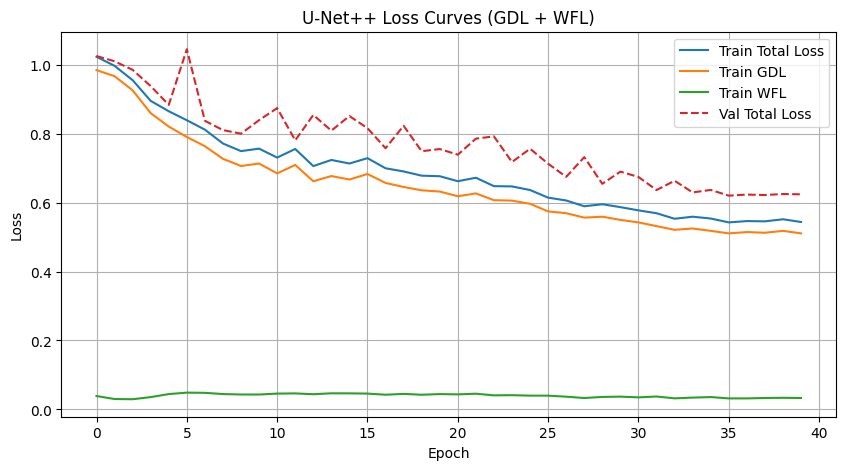

In [11]:
MODEL_NAME = "U-Net++"
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train Total Loss")
plt.plot(history["train_gdl"], label="Train GDL")
plt.plot(history["train_wfl"], label="Train WFL")
plt.plot(history["val_loss"], label="Val Total Loss", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"{MODEL_NAME} Loss Curves (GDL + WFL)")
plt.legend()
plt.grid(True)
plt.show()


## 10. Model Evaluation on Full Test Set (Non-Overlapping Patches)

In [ ]:
eval_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=config["patch_size"],  # non-overlapping evaluation
    augment=False,
    cache_in_memory=False,
    load_s1=False,
)
eval_loader = DataLoader(eval_dataset, batch_size=64, shuffle=False, num_workers=0)

model.eval()
tp = np.zeros(6, dtype=np.int64)
fp = np.zeros(6, dtype=np.int64)
fn = np.zeros(6, dtype=np.int64)
class_pixel_counts = np.zeros(6, dtype=np.int64)

with torch.no_grad():
    for s2_patches, _, gt_patches in eval_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.numpy()

        logits = model(s2_patches)
        preds = torch.argmax(logits, dim=1).cpu().numpy()

        for b in range(preds.shape[0]):
            pred_b = preds[b]
            gt_b = gt_patches[b]
            valid_mask = gt_b < 6

            for c in range(6):
                pred_c = (pred_b == c) & valid_mask
                gt_c = (gt_b == c) & valid_mask

                tp[c] += np.sum(pred_c & gt_c)
                fp[c] += np.sum(pred_c & ~gt_c)
                fn[c] += np.sum(~pred_c & gt_c)
                class_pixel_counts[c] += np.sum(gt_c)

class_names = [
    "Open surface water (2)",
    "Soil seriously affected (3)",
    "Soil moderately affected (4)",
    "Soil slightly affected (5)",
    "Vegetation affected (6)",
    "Not affected areas (7)",
]

print("\n" + "=" * 70)
print(f"{'Class ID':<10}{'Class Name':<45}{'Pr (%)':<10}{'Rc (%)':<10}{'F1 (%)':<10}")
print("=" * 70)

precision_list, recall_list, f1_list = [], [], []
for c in range(6):
    pr = tp[c] / (tp[c] + fp[c] + 1e-10)
    rc = tp[c] / (tp[c] + fn[c] + 1e-10)
    f1 = 2 * pr * rc / (pr + rc + 1e-10)

    precision_list.append(pr)
    recall_list.append(rc)
    f1_list.append(f1)

    print(f"{c:<10}{class_names[c]:<45}{pr * 100:<10.2f}{rc * 100:<10.2f}{f1 * 100:<10.2f}")

print("=" * 70)
total_valid_pixels = class_pixel_counts.sum()
class_weights_eval = class_pixel_counts / total_valid_pixels
overall_pr = np.sum(np.array(precision_list) * class_weights_eval)
overall_rc = np.sum(np.array(recall_list) * class_weights_eval)
overall_f1 = np.sum(np.array(f1_list) * class_weights_eval)
print(f"{'ALL':<10}{'Overall (Pixel-Weighted, classes 2-7)':<45}{overall_pr * 100:<10.2f}{overall_rc * 100:<10.2f}{overall_f1 * 100:<10.2f}")
print("=" * 70)

# --- Paper-comparable metric ------------------------------------------------
# Table 1 in the paper computes Pr/Rc/F1 over classes 2-6 ONLY (water + the 4 soil/vegetation
# severity classes), explicitly excluding class 7 ("not affected", ~87% of pixels). Including
# class 7 in the weighted average above makes the "ALL" row look far higher (94%+) than the
# paper's reported numbers (~79-81%) simply because the easy majority class dominates the
# weighting - it is NOT an apples-to-apples comparison. This second row is.
water_classes_weights = class_pixel_counts[:5] / class_pixel_counts[:5].sum()
paper_pr = np.sum(np.array(precision_list[:5]) * water_classes_weights)
paper_rc = np.sum(np.array(recall_list[:5]) * water_classes_weights)
paper_f1 = np.sum(np.array(f1_list[:5]) * water_classes_weights)
print(f"\n{'PAPER':<10}{'Table-1-comparable (Pixel-Weighted, classes 2-6 only)':<55}{paper_pr * 100:<10.2f}{paper_rc * 100:<10.2f}{paper_f1 * 100:<10.2f}")
print(f"{'':10}{'  vs. paper U-Net++ Table 1: Pr=77.61  Rc=80.87  F1=79.10':<55}")


## 11. Visualizing Predictions

In [ ]:
# Pick patches by GT class diversity instead of arbitrary fixed indices - most patches are
# 80%+ "not affected" (class 5, i.e. raw class 7), so a naive fixed stride mostly lands on
# near-uniform crops that make the model (and the data) look duller than they are. Scanning
# for the most class-diverse patches gives a genuinely informative qualitative comparison.
def patch_class_diversity(idx):
    _, _, gt = eval_dataset[idx]
    gt_np = gt.numpy()
    valid = gt_np[gt_np < 6]
    return len(np.unique(valid)) if valid.size else 0

scan_indices = range(0, len(eval_dataset), 37)  # coarse scan (37 avoids aliasing with the patch grid)
diversity_scores = sorted(
    ((idx, patch_class_diversity(idx)) for idx in scan_indices),
    key=lambda t: t[1], reverse=True,
)
chosen = [idx for idx, _ in diversity_scores[:3]]
print(f"Chosen patches (by GT class diversity): {[(idx, s) for idx, s in diversity_scores[:3]]}")

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, patch_idx in enumerate(chosen):
    s2, _, gt = eval_dataset[patch_idx]

    s2_in = s2.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(s2_in)
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    s2_np = s2.numpy()
    rgb = np.stack([s2_np[3], s2_np[2], s2_np[1]], axis=-1)
    rgb = rgb * S2_STD[[3, 2, 1]] + S2_MEAN[[3, 2, 1]]  # undo standardization -> reflectance
    rgb = stretch_rgb(rgb)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Input RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt.numpy(), cmap="tab10", vmin=0, vmax=5)
    axes[i, 1].set_title("GT Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(pred, cmap="tab10", vmin=0, vmax=5)
    axes[i, 2].set_title(f"{MODEL_NAME} Prediction")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()
